## Business Understanding

### Permasalahan
Informasi mengenai persebaran tutupan lahan diperlukan untuk memahami kondisi permukaan bumi di Jawa Timur. Pengamatan secara langsung terhadap seluruh wilayah membutuhkan waktu dan biaya, sehingga citra satelit dapat dimanfaatkan untuk memperoleh gambaran wilayah secara lebih luas.

### Tujuan utama
Membuat peta tutupan permukaan bumi di Jawa Timur menggunakan citra satelit Sentinel-2 dan metode Random Forest untuk mengelompokkan piksel citra menjadi lima kelas tutupan lahan.

### Hasil yang diharapkan
Peta tematik yang menunjukkan lokasi dan persebaran bangunan, lahan pertanian, badan air, hutan, dan hutan mangrove, disertai evaluasi akurasi model dan perkiraan luas setiap kelas.

### Kelas yang akan dipetakan
- **Kelas:** Bangunan, Lahan pertanian, Perairan, Hutan, dan Mangrove.
- **Algoritma utama:** Random Forest.

### Apa tujuan penggunaan citra satelit dan Random Forest?
- **Citra satelit Sentinel-2:** menyediakan informasi spektral permukaan bumi yang dapat digunakan untuk membedakan karakteristik tutupan lahan.
- **Band Sentinel-2:** menyediakan informasi spektral yang digunakan sebagai fitur masukan model.
- **Random Forest:** mempelajari pola dari sampel yang sudah memiliki label kelas, kemudian memprediksi kelas pada piksel citra lainnya.
- **Evaluasi model:** mengukur seberapa baik hasil prediksi sesuai dengan label sampel pengujian.
- **Peta hasil klasifikasi:** menyajikan hasil prediksi secara geografis agar persebaran tutupan lahan lebih mudah dipahami.

## 1. Import pustaka dan atur lokasi file

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.warp import transform as transform_coords
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image
import folium
from folium.raster_layers import ImageOverlay
from IPython.display import display
warnings.filterwarnings("ignore", category=UserWarning)

BASE = Path.cwd()
SAMPLE_FILE = BASE / "jawaTimur.geojson"
CLIP_DIR = BASE / "Browser_images"
RAW_DIR = BASE / "data"
BOUNDARY_FILE = BASE / "lokasi.geojson"
BANDS = ["B02", "B03", "B04", "B08", "B8A", "B11"]
TARGET_CLASSES = ["Hutan", "Perairan", "Lahan pertanian", "Bangunan", "Mangrove"]
COLORS = {"Hutan":"#228B22", "Perairan":"#1E90FF", "Lahan pertanian":"#FFD34E", "Bangunan":"#D73027", "Mangrove":"#7B3294"}
print("Folder kerja:", BASE)
print("File sampel:", SAMPLE_FILE, "| ditemukan:", SAMPLE_FILE.exists())
if not SAMPLE_FILE.exists():
    raise FileNotFoundError("File jawaTimur.geojson tidak ditemukan. Letakkan file tersebut di folder kerja notebook.")

Folder kerja: c:\Users\LENOVO\PSD\pertemuan_6
File sampel: c:\Users\LENOVO\PSD\pertemuan_6\jawaTimur.geojson | ditemukan: True


## 2. Baca sampel dan normalisasi lima kelas

In [2]:
samples = gpd.read_file(SAMPLE_FILE)
print("Jumlah sampel:", len(samples))
print("CRS sampel:", samples.crs)
print("Kolom:", samples.columns.tolist())
if samples.crs is None:
    raise ValueError("CRS file sampel tidak terdefinisi. Tetapkan CRS yang benar terlebih dahulu.")

candidates = ["class_name", "kelas_rf", "kelas", "class", "label", "nama_kelas", "tutupan_lahan", "landcover", "jenis", "nama", "kategori", "original_category"]
label_col = next((c for c in candidates if c in samples.columns), None)
if label_col is None:
    raise ValueError(f"Kolom label kelas tidak ditemukan. Kolom tersedia: {samples.columns.tolist()}")
print("Kolom label:", label_col)
print("Label asli:\n", samples[label_col].value_counts(dropna=False))

def normalize_label(value):
    if pd.isna(value): return np.nan
    t = " ".join(str(value).strip().casefold().replace("_", " ").split())
    if "mangrove" in t: return "Mangrove"
    if "hutan" in t or "forest" in t: return "Hutan"
    if "perairan" in t or "water" in t or "badan air" in t: return "Perairan"
    if "pertanian" in t or "cropland" in t or "agriculture" in t: return "Lahan pertanian"
    if "bangunan" in t or "built-up" in t or "built up" in t or "builtup" in t: return "Bangunan"
    return np.nan

samples["kelas_rf"] = samples[label_col].apply(normalize_label)
print("\nHasil normalisasi:\n", samples["kelas_rf"].value_counts(dropna=False))
missing = sorted(set(TARGET_CLASSES) - set(samples["kelas_rf"].dropna().unique()))
if missing:
    raise ValueError(f"Kelas belum dikenali: {missing}. Periksa daftar Label asli yang dicetak di atas.")
samples = samples[samples["kelas_rf"].notna() & samples.geometry.notna()].copy()
print("Sampel yang dipakai:", len(samples))

Jumlah sampel: 350
CRS sampel: EPSG:4326
Kolom: ['sample_id', 'class_name', 'class_id', 'source_file', 'source_index', 'original_category', 'geometry']
Kolom label: class_name
Label asli:
 class_name
Hutan                    70
Perairan / Water body    70
Lahan pertanian          70
Bangunan                 70
Mangrove                 70
Name: count, dtype: int64

Hasil normalisasi:
 kelas_rf
Hutan              70
Perairan           70
Lahan pertanian    70
Bangunan           70
Mangrove           70
Name: count, dtype: int64
Sampel yang dipakai: 350


## 3. Pilih raster yang benar dan validasi datanya

In [3]:
def find_band_file(folder, band):
    if not folder.exists(): return None
    # Cari nama seperti B02.tif, Txx_B02_....tif, atau B02_clip.tif
    candidates = list(folder.rglob("*.tif")) + list(folder.rglob("*.tiff"))
    exact = [p for p in candidates if p.stem.upper() == band.upper()]
    if exact: return exact[0]
    matches = [p for p in candidates if band.upper() in p.stem.upper() and "TRUE_COLOR" not in p.stem.upper()]
    # Prioritaskan nama band asli, lalu file clip
    matches.sort(key=lambda p: ("clip" in p.stem.lower(), len(p.name)))
    return matches[0] if matches else None

clip_files = {b: CLIP_DIR / f"{b}_clip.tif" for b in BANDS}
raw_files = {b: find_band_file(RAW_DIR, b) for b in BANDS}

def raster_has_data(path):
    if path is None or not Path(path).exists(): return False
    try:
        with rasterio.open(path) as src:
            a = src.read(1, masked=True)
            v = a.compressed()
            return v.size > 0 and np.any(v != 0)
    except Exception:
        return False

clip_ok = all(raster_has_data(clip_files[b]) for b in BANDS)
raw_ok = all(raster_has_data(raw_files[b]) for b in BANDS)
if clip_ok:
    RASTER_FILES = clip_files
    print("Menggunakan raster hasil clip.")
elif raw_ok:
    RASTER_FILES = raw_files
    print("PERINGATAN: raster hasil clip kosong/berisi nol. Menggunakan raster asli dari folder jawa_timur sebagai gantinya.")
else:
    details = []
    for b in BANDS:
        for label, path in [("clip", clip_files[b]), ("asli", raw_files[b])]:
            if path and Path(path).exists():
                with rasterio.open(path) as src:
                    a = src.read(1, masked=True).compressed()
                    details.append(f"{b} {label}: {path} | min={a.min() if a.size else 'kosong'} | max={a.max() if a.size else 'kosong'}")
            else: details.append(f"{b} {label}: file tidak ditemukan")
    raise RuntimeError("Tidak ada kumpulan enam band yang berisi data valid. Pastikan TIFF Sentinel-2 asli tersedia di folder jawa_timur/.\n" + "\n".join(details))

for b, path in RASTER_FILES.items(): print(b, "->", path)

PERINGATAN: raster hasil clip kosong/berisi nol. Menggunakan raster asli dari folder jawa_timur sebagai gantinya.
B02 -> c:\Users\LENOVO\PSD\pertemuan_6\data\B02_gabungan.tiff
B03 -> c:\Users\LENOVO\PSD\pertemuan_6\data\B03_gabungan.tiff
B04 -> c:\Users\LENOVO\PSD\pertemuan_6\data\B04_gabungan.tiff
B08 -> c:\Users\LENOVO\PSD\pertemuan_6\data\B08_gabungan.tiff
B8A -> c:\Users\LENOVO\PSD\pertemuan_6\data\B8A_gabungan.tiff
B11 -> c:\Users\LENOVO\PSD\pertemuan_6\data\B11_gabungan.tiff


## 4. Baca stack band dan siapkan mask piksel valid

In [4]:
srcs = {b: rasterio.open(path) for b, path in RASTER_FILES.items()}
reference = srcs["B02"]
profile = reference.profile.copy()
height, width = reference.height, reference.width
print("Ukuran raster:", width, "x", height)
print("CRS raster:", reference.crs)
print("Bounds:", reference.bounds)

for b, src in srcs.items():
    if (src.width, src.height, src.transform, src.crs) != (reference.width, reference.height, reference.transform, reference.crs):
        for s in srcs.values(): s.close()
        raise ValueError(f"Grid band {b} berbeda. Semua band harus punya ukuran, transformasi, dan CRS yang sama.")

stack = np.stack([srcs[b].read(1).astype(np.float32) for b in BANDS], axis=0)
valid_mask = np.all(np.isfinite(stack), axis=0)
for i, b in enumerate(BANDS):
    nd = srcs[b].nodata
    if nd is not None: valid_mask &= stack[i] != nd
valid_mask &= ~np.all(stack == 0, axis=0)
print("Piksel valid:", int(valid_mask.sum()), "/", height * width)
if not valid_mask.any():
    raise RuntimeError("Tidak ada piksel valid pada raster yang dipilih. Periksa sumber TIFF dan nilai NoData.")

Ukuran raster: 2500 x 1452
CRS raster: EPSG:4326
Bounds: BoundingBox(left=110.690002, bottom=-8.904041, right=114.78, top=-6.55)
Piksel valid: 3147483 / 3630000


## 5. Ekstrak nilai band pada sampel

In [5]:
# Konversi sampel ke CRS raster. Untuk poligon gunakan representative_point yang berada di dalam geometri.
samp_raster = samples.to_crs(reference.crs)
coords = []
labels = []
for _, row in samp_raster.iterrows():
    geom = row.geometry
    if geom is None or geom.is_empty: continue
    pt = geom if geom.geom_type == "Point" else geom.representative_point()
    coords.append((pt.x, pt.y))
    labels.append(row["kelas_rf"])

X_rows, y_rows = [], []
for (x, ycoord), label in zip(coords, labels):
    try:
        vals = []
        for b in BANDS:
            v = next(srcs[b].sample([(x, ycoord)]))[0]
            vals.append(float(v))
        vals = np.asarray(vals, dtype=np.float32)
        if np.all(np.isfinite(vals)) and not np.all(vals == 0):
            # Buang sampel yang berada di luar extent atau di piksel NoData
            rowcol = reference.index(x, ycoord)
            rr, cc = rowcol
            if 0 <= rr < height and 0 <= cc < width and valid_mask[rr, cc]:
                X_rows.append(vals)
                y_rows.append(label)
    except Exception:
        continue

X = np.asarray(X_rows, dtype=np.float32).reshape((-1, len(BANDS)))
y = np.asarray(y_rows, dtype=str)
print("Sampel valid untuk training:", len(y))
print(pd.Series(y).value_counts())
if len(y) == 0:
    raise RuntimeError("Sampel tidak jatuh pada piksel raster valid. Periksa CRS dan bounds raster/sampel. Jika raster asli yang dipakai, pastikan sampel berada dalam cakupan citra.")
if len(np.unique(y)) < 2:
    raise RuntimeError("Sampel valid hanya berisi satu kelas. Periksa lokasi sampel dan cakupan raster.")

Sampel valid untuk training: 350
Hutan              70
Perairan           70
Lahan pertanian    70
Bangunan           70
Mangrove           70
Name: count, dtype: int64


## 6. Latih dan evaluasi Random Forest

In [6]:
counts = pd.Series(y).value_counts()
stratify_arg = y if len(counts) > 1 and counts.min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=stratify_arg)
model = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Akurasi:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, labels=TARGET_CLASSES, zero_division=0))
print("Confusion matrix (urutan kelas tetap):")
print(pd.DataFrame(confusion_matrix(y_test, y_pred, labels=TARGET_CLASSES), index=TARGET_CLASSES, columns=TARGET_CLASSES))

Akurasi: 0.75
                 precision    recall  f1-score   support

          Hutan       0.65      0.76      0.70        17
       Perairan       0.75      0.88      0.81        17
Lahan pertanian       0.69      0.61      0.65        18
       Bangunan       0.76      0.72      0.74        18
       Mangrove       0.93      0.78      0.85        18

       accuracy                           0.75        88
      macro avg       0.76      0.75      0.75        88
   weighted avg       0.76      0.75      0.75        88

Confusion matrix (urutan kelas tetap):
                 Hutan  Perairan  Lahan pertanian  Bangunan  Mangrove
Hutan               13         2                2         0         0
Perairan             0        15                0         1         1
Lahan pertanian      3         1               11         3         0
Bangunan             2         0                3        13         0
Mangrove             2         2                0         0        14


## 7. Klasifikasikan piksel dan simpan GeoTIFF

In [7]:
X_all = stack[:, valid_mask].T

y_pred_all = model.predict(X_all)


class_to_idx = {c: i + 1 for i, c in enumerate(TARGET_CLASSES)}
y_pred_idx = np.array([class_to_idx[val] for val in y_pred_all], dtype=np.uint8)

# Buat array kosong dengan dimensi citra asli
out_img = np.zeros((height, width), dtype=np.uint8)
out_img[valid_mask] = y_pred_idx
print("Piksel terklasifikasi:", int(valid_mask.sum()))

# Menyimpan hasil klasifikasi ke dalam format GeoTIFF
out_meta = profile.copy()
out_meta.update({
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": rasterio.uint8,
    "nodata": 0
})

OUT_TIF = BASE / "Hasil_Klasifikasi_Jatim.tif"
with rasterio.open(OUT_TIF, "w", **out_meta) as dest:
    dest.write(out_img, 1)

print("Peta GeoTIFF berhasil disimpan di:", OUT_TIF)

Piksel terklasifikasi: 3147483
Peta GeoTIFF berhasil disimpan di: c:\Users\LENOVO\PSD\pertemuan_6\Hasil_Klasifikasi_Jatim.tif


Piksel terklasifikasi: 3147483


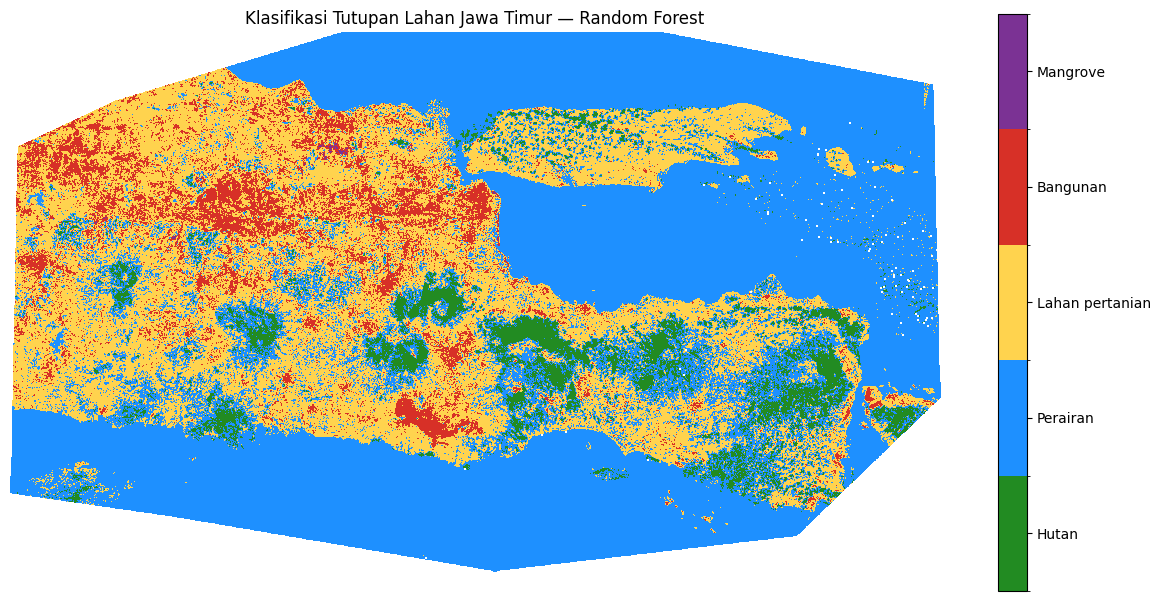

GeoTIFF tersimpan: c:\Users\LENOVO\PSD\pertemuan_6\hasil_klasifikasi_jatim.tif


In [8]:
class_to_id = {name: i + 1 for i, name in enumerate(TARGET_CLASSES)}
pred_map = np.zeros((height, width), dtype=np.uint8)
rows, cols = np.where(valid_mask)
pixel_matrix = stack[:, rows, cols].T.astype(np.float32)
batch_size = 100_000
for start in range(0, len(pixel_matrix), batch_size):
    pred = model.predict(pixel_matrix[start:start + batch_size])
    pred_map[rows[start:start + len(pred)], cols[start:start + len(pred)]] = np.asarray([class_to_id[str(c)] for c in pred], dtype=np.uint8)
print("Piksel terklasifikasi:", int((pred_map > 0).sum()))

cmap = mcolors.ListedColormap([COLORS[c] for c in TARGET_CLASSES])
norm = mcolors.BoundaryNorm(np.arange(0.5, len(TARGET_CLASSES) + 1.5, 1), cmap.N)
plt.figure(figsize=(12, 8))
plt.imshow(np.ma.masked_where(pred_map == 0, pred_map), cmap=cmap, norm=norm)
cb = plt.colorbar(ticks=np.arange(1, len(TARGET_CLASSES) + 1), shrink=0.75)
cb.ax.set_yticklabels(TARGET_CLASSES)
plt.title("Klasifikasi Tutupan Lahan Jawa Timur — Random Forest")
plt.axis("off"); plt.tight_layout(); plt.show()

out_tif = BASE / "hasil_klasifikasi_jatim.tif"
out_profile = profile.copy(); out_profile.update(count=1, dtype="uint8", nodata=0, compress="lzw")
with rasterio.open(out_tif, "w", **out_profile) as dst: dst.write(pred_map, 1)
print("GeoTIFF tersimpan:", out_tif)

## 8. Buat PNG overlay dan peta interaktif

PNG overlay berhasil dibuat di: c:\Users\LENOVO\PSD\pertemuan_6\Overlay_Klasifikasi.png



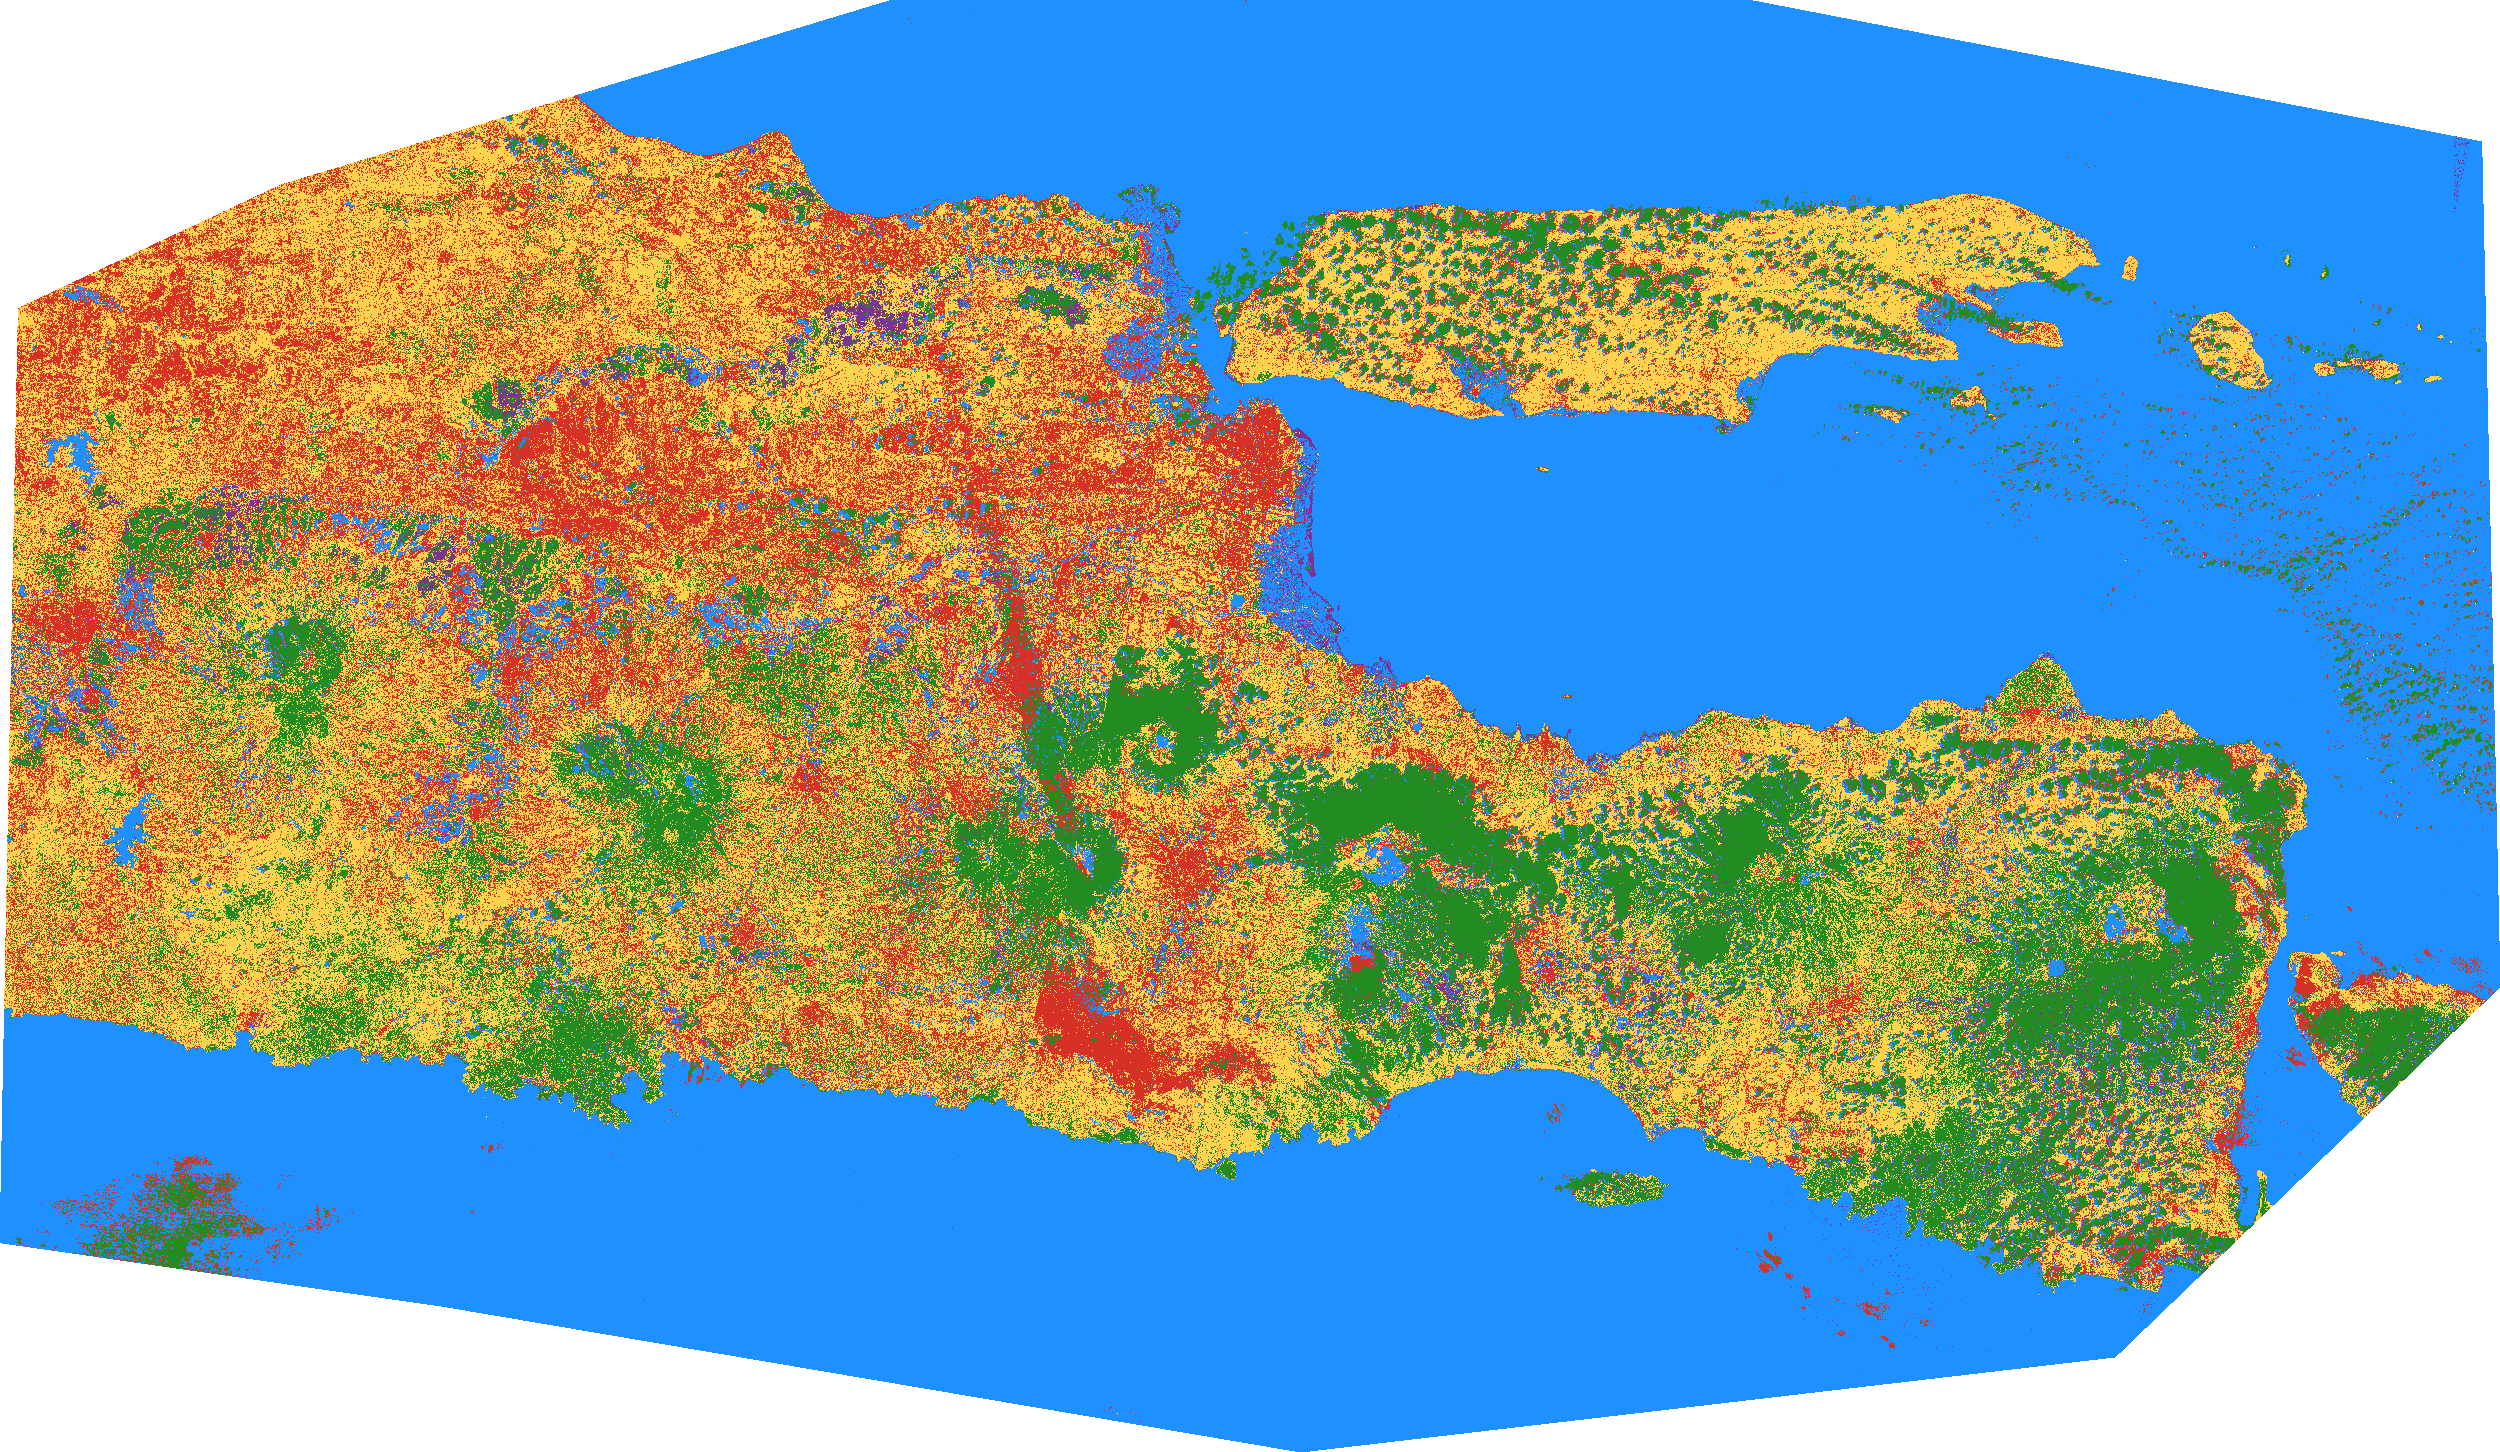

In [9]:
colored_img = np.zeros((height, width, 4), dtype=np.uint8)


for i, c in enumerate(TARGET_CLASSES):
    idx = i + 1
    rgb = mcolors.to_rgba(COLORS[c])
    r, g, b, a = [int(x * 255) for x in rgb]
    
    mask = (out_img == idx)
    colored_img[mask] = [r, g, b, 255] 
    
OUT_PNG = BASE / "Overlay_Klasifikasi.png"
Image.fromarray(colored_img).save(OUT_PNG)
print("PNG overlay berhasil dibuat di:", OUT_PNG)

bounds = reference.bounds
min_lon, min_lat, max_lon, max_lat = bounds.left, bounds.bottom, bounds.right, bounds.top
center_lat = (min_lat + max_lat) / 2
center_lon = (min_lon + max_lon) / 2

m = folium.Map(location=[center_lat, center_lon], zoom_start=8, tiles="CartoDB positron")

ImageOverlay(
    image=str(OUT_PNG),
    bounds=[[min_lat, min_lon], [max_lat, max_lon]],
    opacity=0.8,
    name="Klasifikasi Tutupan Lahan"
).add_to(m)

folium.LayerControl().add_to(m)

display(m)

Memulai klasifikasi untuk seluruh area...
Klasifikasi selesai.
Membangun layer interaktif per kelas...
Peta interaktif dengan poligon dan slider berhasil disimpan di: c:\Users\LENOVO\PSD\pertemuan_6\peta_klasifikasi_jatim_lengkap.html



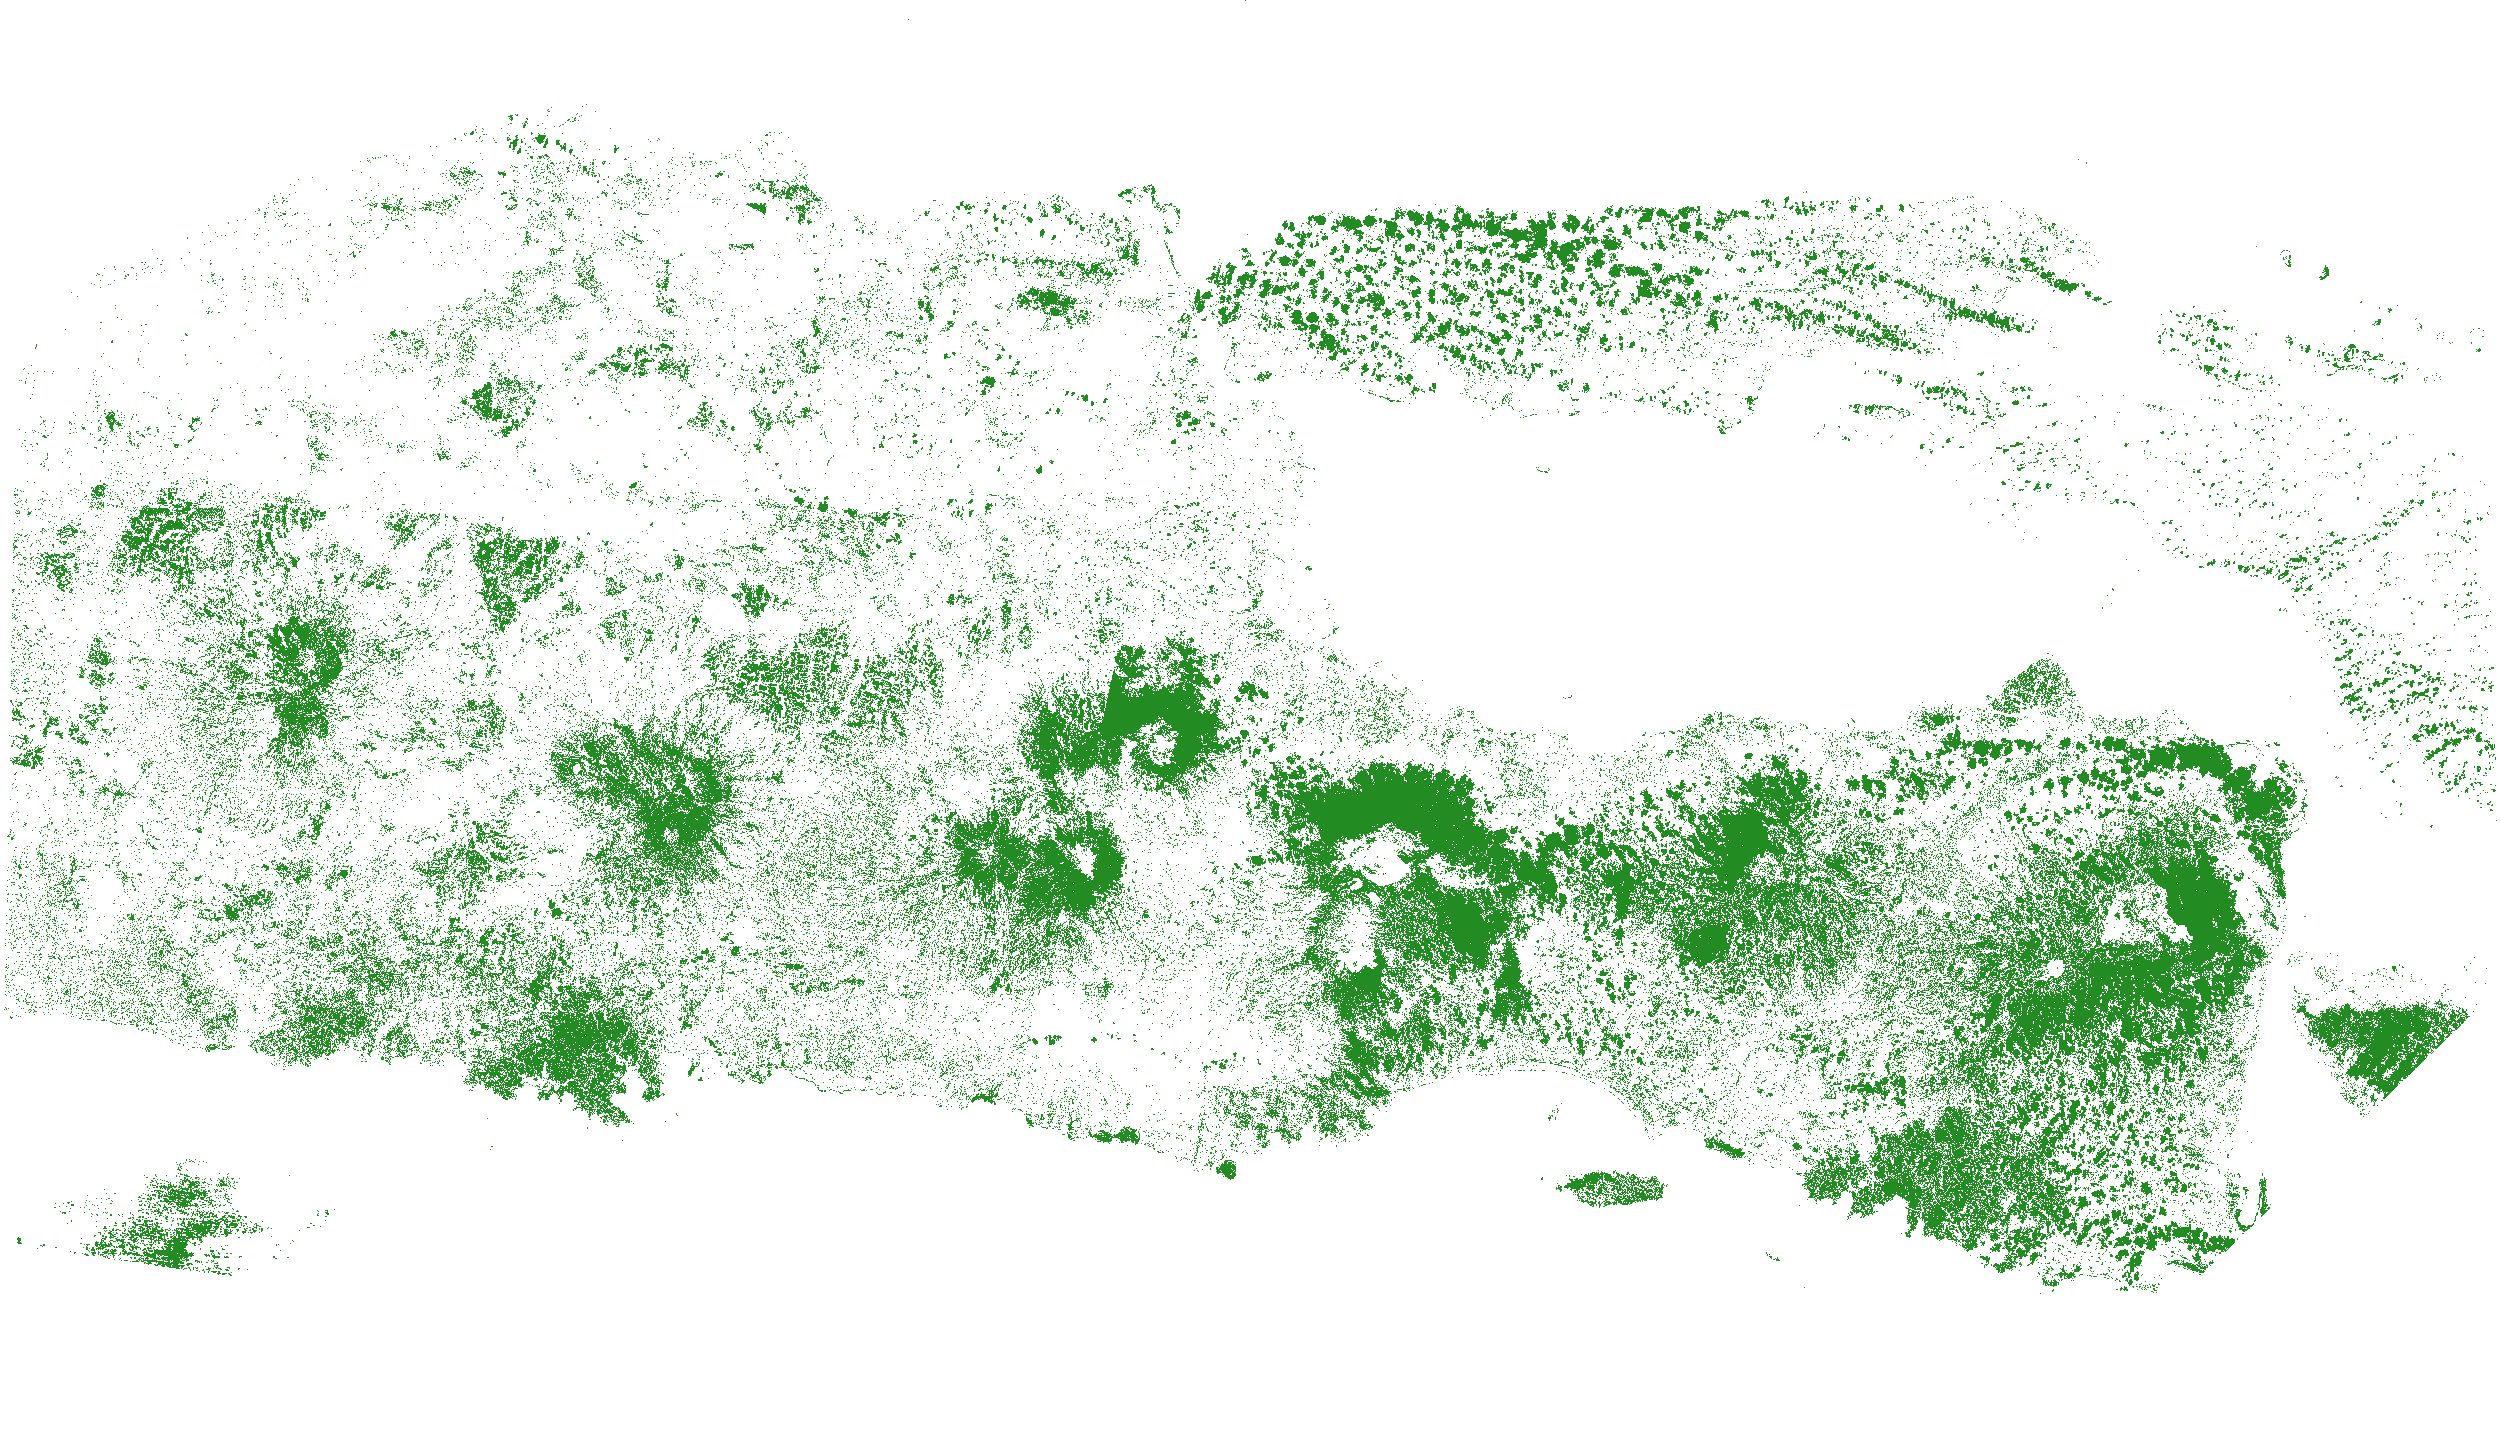
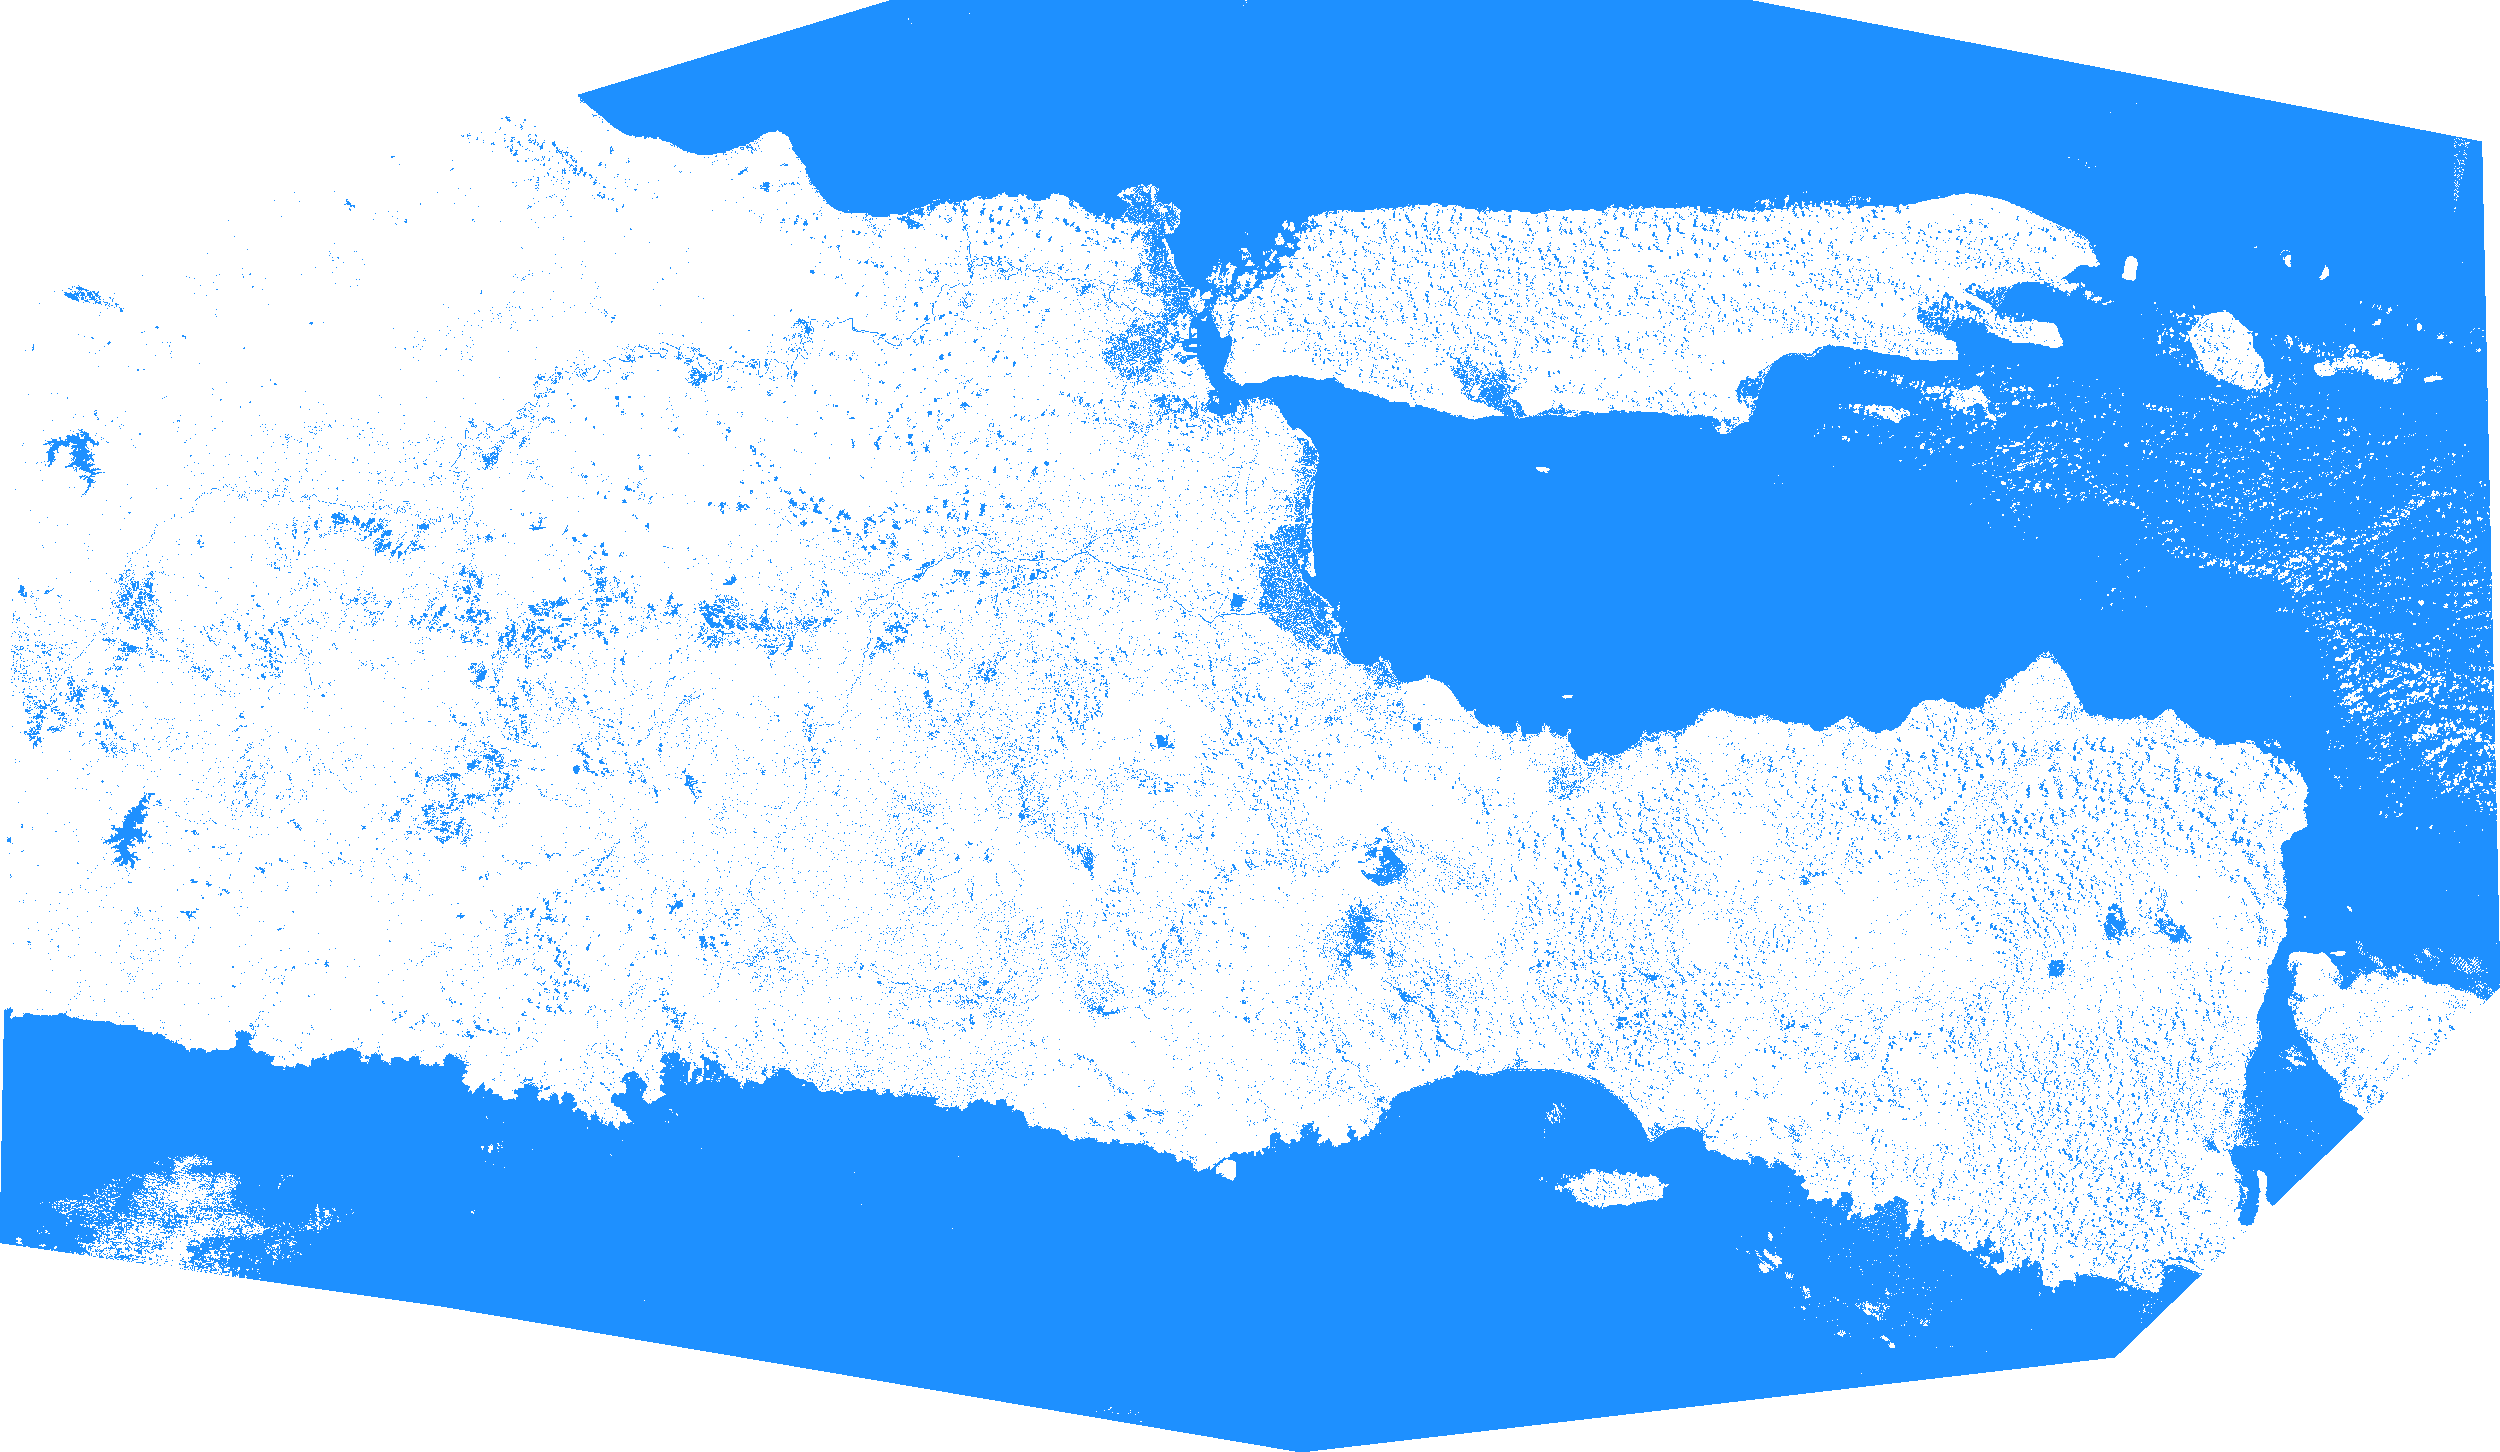
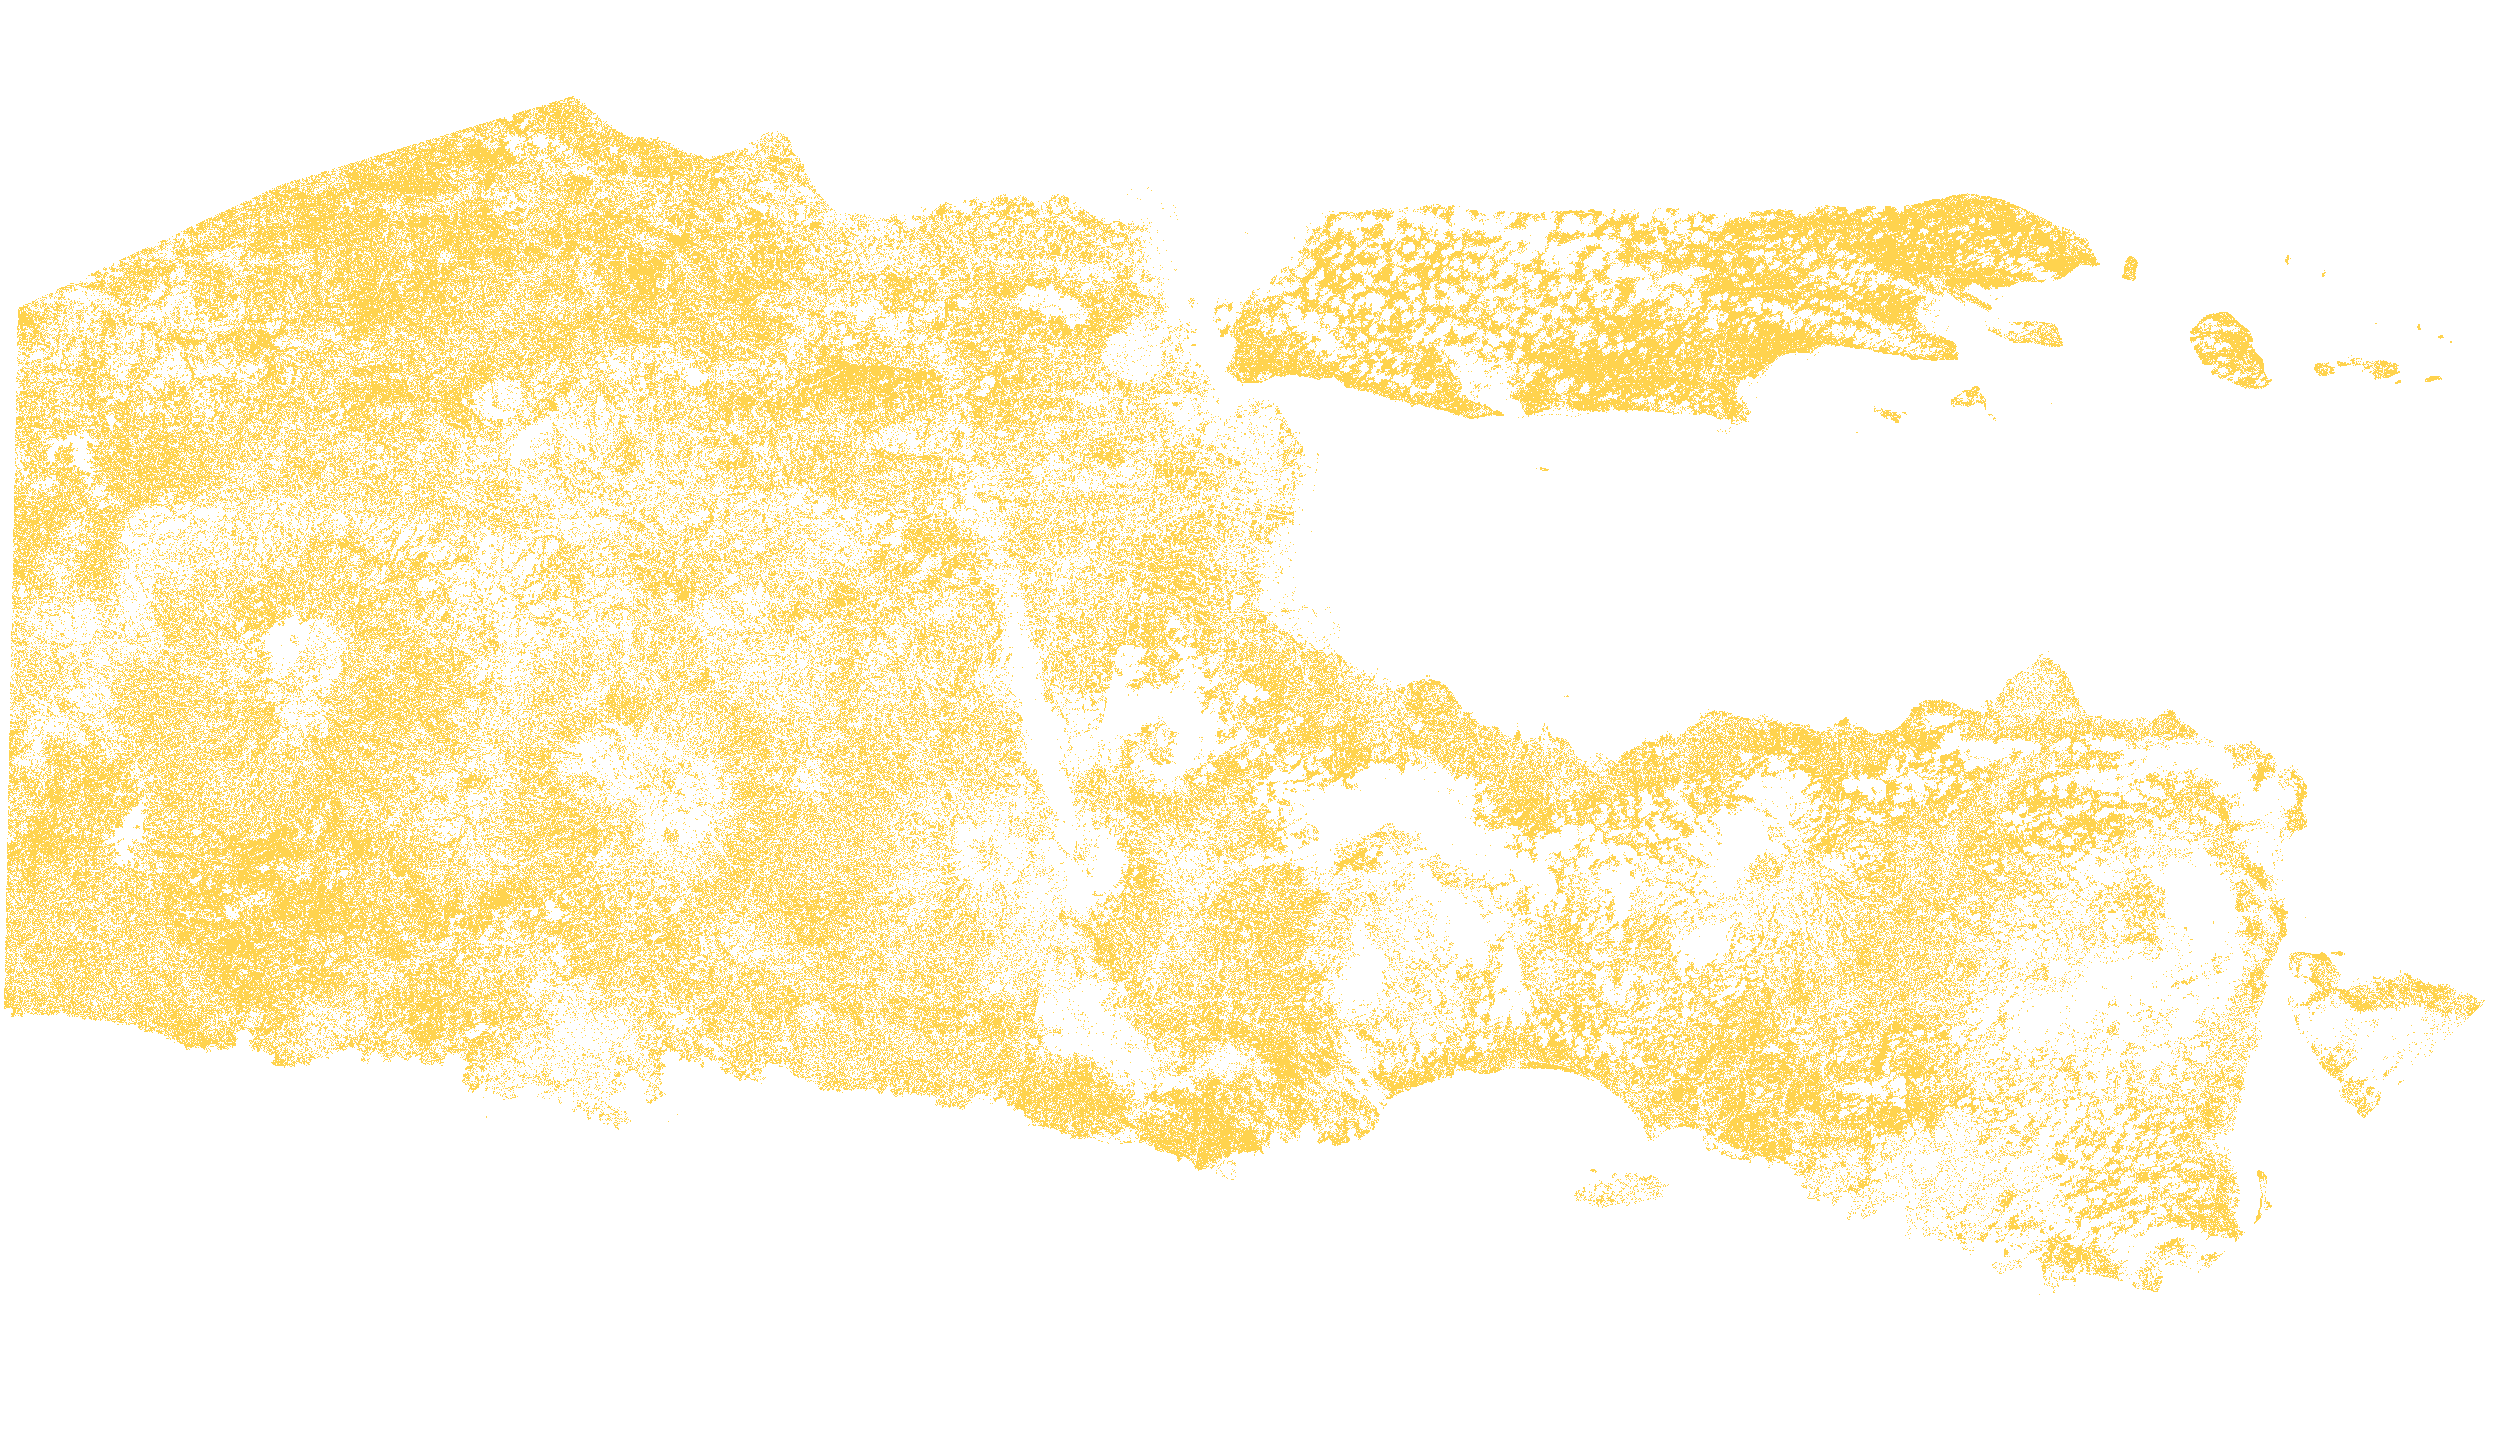
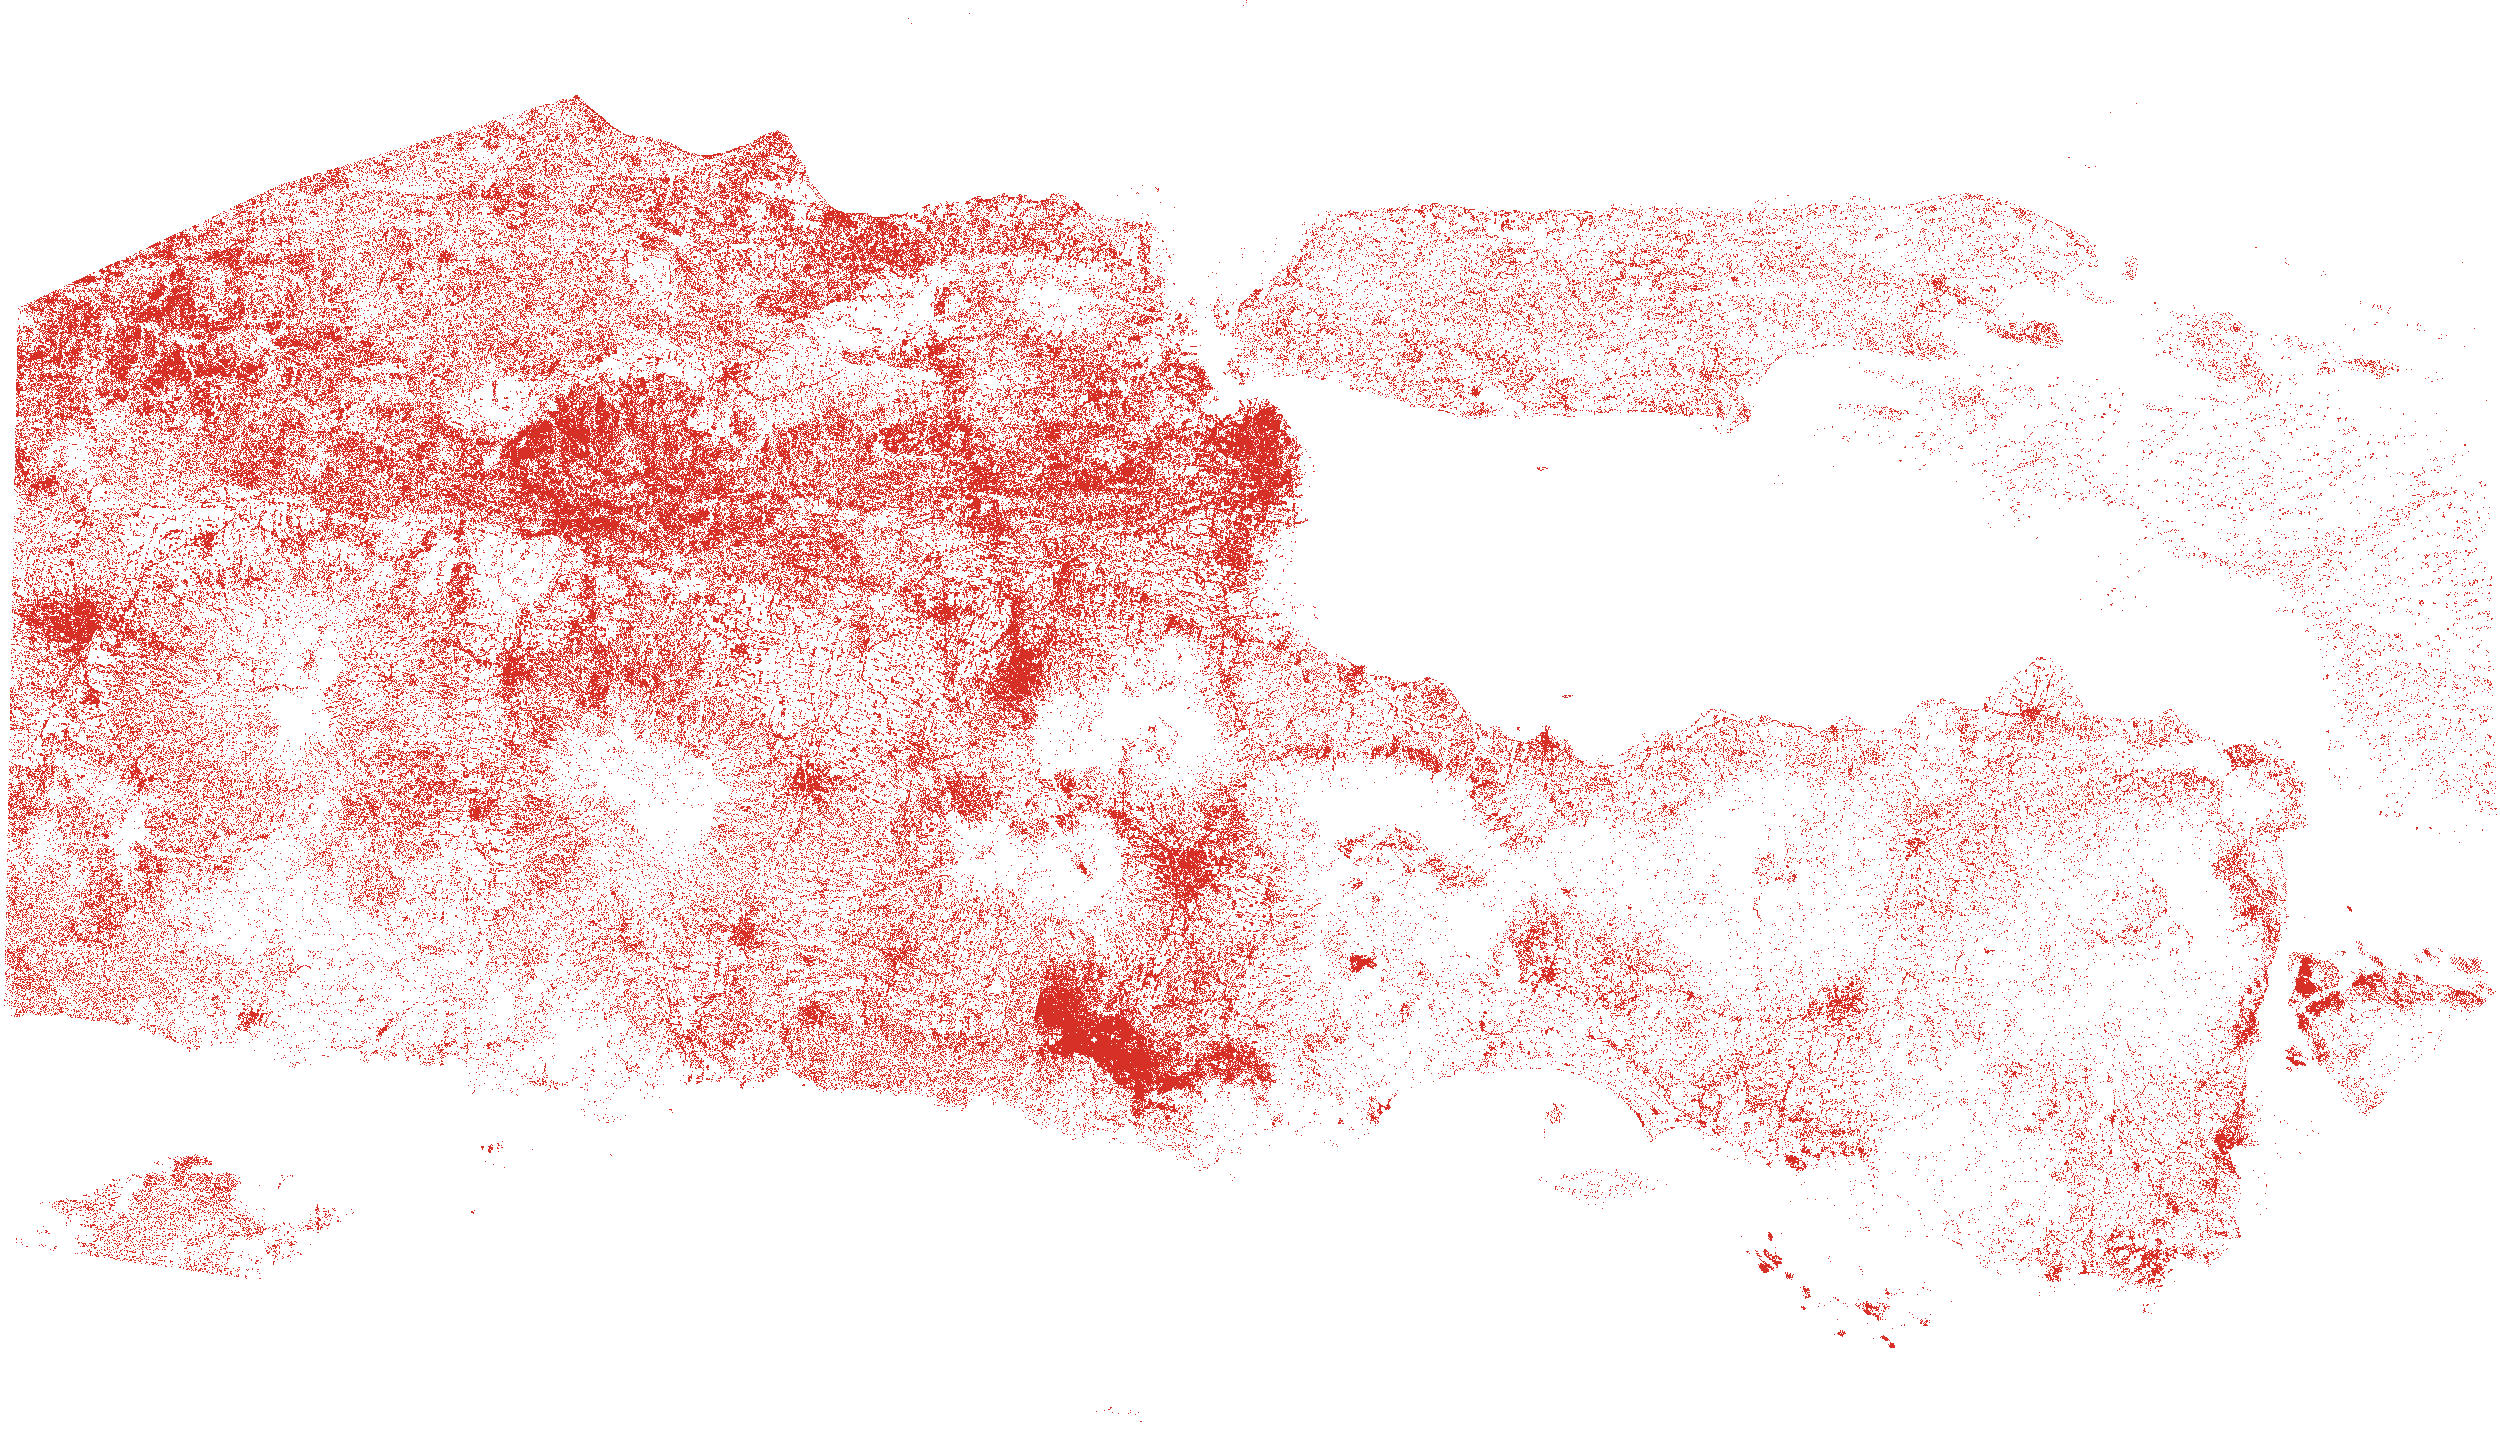
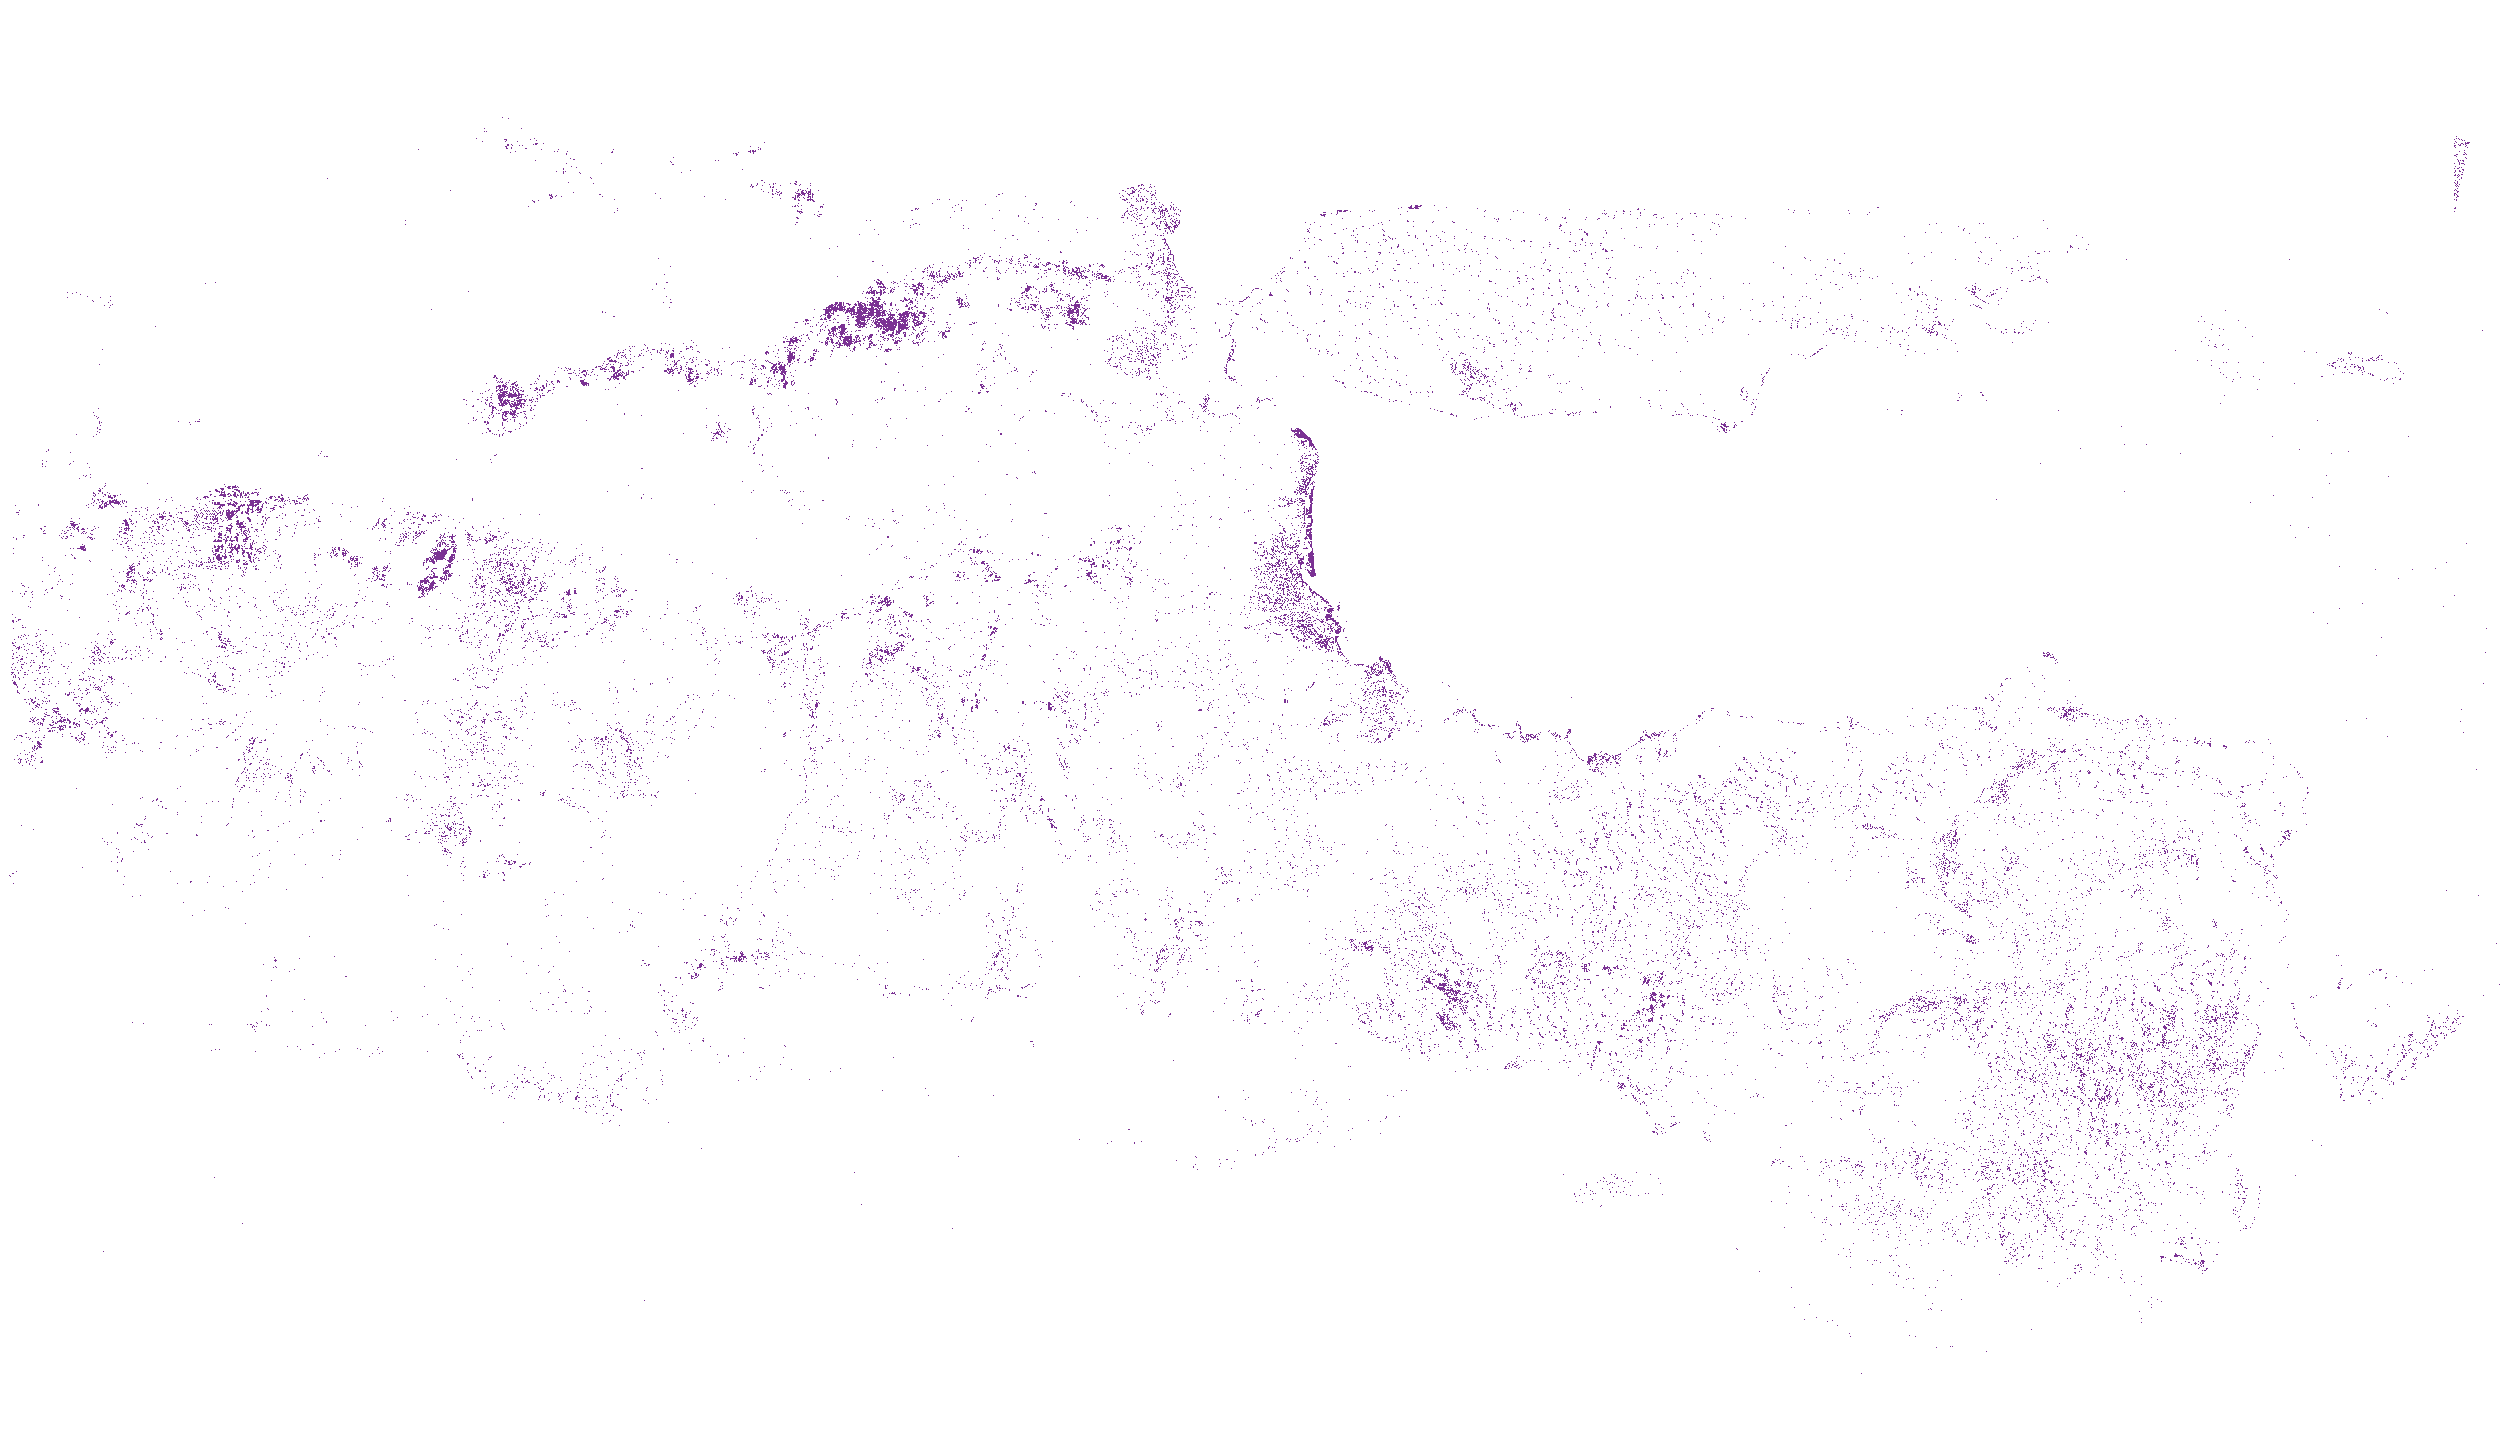

In [10]:
import folium
from folium import raster_layers, Element
import matplotlib.colors as mcolors
import numpy as np
import geopandas as gpd
from rasterio.warp import transform_bounds

print("Memulai klasifikasi untuk seluruh area...")
X_all = stack[:, valid_mask].T
y_pred_all = model.predict(X_all)
print("Klasifikasi selesai.")

bounds_latlon = transform_bounds(reference.crs, 'EPSG:4326', *reference.bounds)
bounds_peta = [
    [bounds_latlon[1], bounds_latlon[0]],
    [bounds_latlon[3], bounds_latlon[2]]
]

pusat_peta = [(bounds_peta[0][0] + bounds_peta[1][0]) / 2, 
              (bounds_peta[0][1] + bounds_peta[1][1]) / 2]

m = folium.Map(location=pusat_peta, zoom_start=8, tiles='OpenStreetMap')

print("Membangun layer interaktif per kelas...")
for cls_name, color_hex in COLORS.items():
    img_rgba = np.zeros((height, width, 4), dtype=np.uint8)
    
    cls_mask = np.zeros(valid_mask.shape, dtype=bool)
    cls_mask[valid_mask] = (y_pred_all == cls_name)
    
    r, g, b = mcolors.to_rgb(color_hex)
    img_rgba[cls_mask, 0] = int(r * 255)
    img_rgba[cls_mask, 1] = int(g * 255)
    img_rgba[cls_mask, 2] = int(b * 255)
    img_rgba[cls_mask, 3] = 255 
    
    if not np.any(cls_mask):
        continue

    fg = folium.FeatureGroup(name=cls_name, overlay=True, control=True)
    
    raster_layers.ImageOverlay(
        image=img_rgba,
        bounds=bounds_peta,
        opacity=0.7,
        interactive=False,
        cross_origin=False,
    ).add_to(fg)
    
    fg.add_to(m)

file_poligon = 'jawaTimur.geojson' 

folium.GeoJson(
    file_poligon,
    name='Poligon Digitasi',
    style_function=lambda feature: {
        'fillColor': 'transparent',
        'color': 'red',
        'weight': 2,
    }
).add_to(m)

slider_html = '''
<div style="position: fixed; top: 120px; left: 20px; z-index: 9999; background-color: white; 
            padding: 10px; border-radius: 8px; box-shadow: 2px 2px 6px rgba(0,0,0,0.3); font-family: Arial;">
    <h4 style="margin: 0 0 5px 0; font-size: 14px;">Hasil klasifikasi</h4>
    <span style="font-size: 12px;">Transparansi</span><br>
    <input type="range" min="0" max="1" step="0.1" value="0.7" oninput="aturTransparansi(this.value)" 
           style="width: 100%; margin-top: 5px;">
</div>

<script>
    function aturTransparansi(nilaiOpacity) {
        var gambarOverlay = document.querySelectorAll('.leaflet-image-layer');
        gambarOverlay.forEach(function(gambar) {
            gambar.style.opacity = nilaiOpacity;
        });
    }
</script>
'''
m.get_root().html.add_child(Element(slider_html))

folium.LayerControl(collapsed=False).add_to(m)

nama_file_html = BASE / "peta_klasifikasi_jatim_lengkap.html" 
m.save(str(nama_file_html))

print(f"Peta interaktif dengan poligon dan slider berhasil disimpan di: {nama_file_html}")

display(m)

## Output

Jika seluruh pemeriksaan berhasil, notebook menghasilkan:
- `hasil_klasifikasi_jatim.tif` — raster hasil klasifikasi.
- `overlay_klasifikasi_jatim.png` — overlay transparan.
- `peta_klasifikasi_jatim.html` — peta interaktif Folium.

**Catatan:** notebook menghindari error lanjutan akibat array kosong dan memperbaiki kesalahan pemetaan warna. Namun, hasil klasifikasi tetap membutuhkan TIFF Sentinel-2 asli yang valid dan mencakup lokasi sampel. Bila sumber citra memang kosong/tidak cocok secara geografis, notebook akan memberi pesan penyebabnya alih-alih menghasilkan peta palsu.

### 12.1 Analisis Confusion Matrix dan Evaluasi Kesalahan Kelas
Confusion matrix digunakan untuk melihat performa model secara detail pada setiap kelas, mengetahui kelas mana saja yang sering tertukar (misalnya lahan pertanian yang keliru diprediksi sebagai hutan atau sebaliknya), serta menghitung matriks evaluasi per kelas (*precision*, *recall*, dan *f1-score*).

<Figure size 800x600 with 0 Axes>

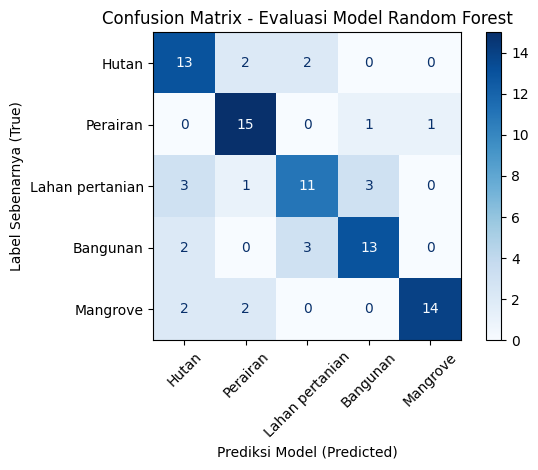


=== Classification Report (Evaluasi Kesalahan per Kelas) ===
                 precision    recall  f1-score   support

          Hutan       0.76      0.72      0.74        18
       Perairan       0.65      0.76      0.70        17
Lahan pertanian       0.69      0.61      0.65        18
       Bangunan       0.93      0.78      0.85        18
       Mangrove       0.75      0.88      0.81        17

       accuracy                           0.75        88
      macro avg       0.76      0.75      0.75        88
   weighted avg       0.76      0.75      0.75        88


=== Analisis Kesalahan (Error Breakdown) ===
- Kelas 'Hutan': 13 benar, 4 salah dari total 17 sampel (Akurasi: 76.47%)
- Kelas 'Perairan': 15 benar, 2 salah dari total 17 sampel (Akurasi: 88.24%)
- Kelas 'Lahan pertanian': 11 benar, 7 salah dari total 18 sampel (Akurasi: 61.11%)
- Kelas 'Bangunan': 13 benar, 5 salah dari total 18 sampel (Akurasi: 72.22%)
- Kelas 'Mangrove': 14 benar, 4 salah dari total 18 sampel (Akur

In [11]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Pastikan model dan data uji (X_test, y_test) sudah tersedia dari tahapan sebelumnya
y_pred_test = model.predict(X_test)

# 1. Menghitung Confusion Matrix menggunakan label target
cm = confusion_matrix(y_test, y_pred_test, labels=TARGET_CLASSES)

# 2. Visualisasi Confusion Matrix dengan ConfusionMatrixDisplay
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=TARGET_CLASSES)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45, values_format='d')
plt.title("Confusion Matrix - Evaluasi Model Random Forest")
plt.xlabel("Prediksi Model (Predicted)")
plt.ylabel("Label Sebenarnya (True)")
plt.tight_layout()
plt.show()

# 3. Menampilkan Laporan Klasifikasi (Precision, Recall, F1-Score)
print("\n=== Classification Report (Evaluasi Kesalahan per Kelas) ===")
report = classification_report(y_test, y_pred_test, target_names=TARGET_CLASSES)
print(report)

# 4. Analisis Detail Jumlah Kesalahan Prediksi per Kelas
print("\n=== Analisis Kesalahan (Error Breakdown) ===")
for i, cls in enumerate(TARGET_CLASSES):
    total_true = cm[i].sum()
    correct = cm[i, i]
    errors = total_true - correct
    accuracy_cls = (correct / total_true) * 100 if total_true > 0 else 0
    print(f"- Kelas '{cls}': {correct} benar, {errors} salah dari total {total_true} sampel (Akurasi: {accuracy_cls:.2f}%)")